## Sandpile simulation and analysis

### Imports

In [1]:
# standard libraries
from pathlib import Path
from collections import deque

# data frame and statistical tools
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score

# for plotting
import matplotlib.pyplot as plt

### Model

In [2]:

class SandPile:
    """SandPile class"""

    def __init__(self, width, height, manna=False, seed=None):
        """Initialize a sandpile with the specified width and height."""
        self.width = width
        self.height = height
        self.manna = manna
        self.rng = np.random.default_rng(seed)
        
        if manna:
            self.threshold = 2
        else:
            self.threshold = 4

        self.grid = np.zeros((width, height), dtype=int)

        # We may want to keep track of the overall mass of the sand pile
        # overtime.  The following array will store the masses at each time
        # step (so that `len(self.mass_history)` is equal to the number of time
        # steps the sand pile has been running).
        self.mass_history = []
        # You probably will want to define other attributes to store statistics.

        # It is good practice to define *all* class attributes in the
        # `__init__` function, even if they get redefined later.  You may want
        # to define variables which are used to keep track of avalanches.
        self.grid_history = []
        

    def drop_sand(self, n=1, site=None):
        """Add `n` grains of sand to the grid.  Each grains of sand is added to
        one random site.

        Return the coordinate of the site sand is dropped.

        Parameters
        ==========

        n: int
            The number of grains of sand of drop at this time step.  If left
            unspecified, defaults to 1.

        site: tuple of int
            The site on which the grain(s) of sand should be dropped.  If `None`,
            a random site is used.

        """

        if site is None:
            coord = self.rng.integers(low = 0, high = [self.width, self.height])
            site = (int(coord[0]), int(coord[1]))
        
        x, y = site

        self.grid[x][y] += n

        return site


    def mass(self):
        """Return the mass of the grid."""
        return np.sum(self.grid)

    def topple(self, site):
        """Topple the specified site under the BTW rule [1]."""
        x, y = site
        self.grid[x][y] -= 4
        loss = 4

        neighbours = ((x+1, y), (x-1, y), (x, y+1), (x, y-1))

        for neighbour in neighbours:
            nx, ny = neighbour
            if (0 <= nx < self.width) and (0 <= ny < self.height):
                self.grid[nx, ny] += 1
                loss -= 1

        return loss
    
    def topple_manna(self, site):
        """Topple the specified site under the Manna rule [2]."""
        x, y = site
        self.grid[x][y] -= 2
        loss = 2

        neighbours = ((x+1, y), (x-1, y), (x, y+1), (x, y-1))

        to_topple = self.rng.choice(len(neighbours), 2, replace=True)

        for i in to_topple:
            nx, ny = neighbours[i]
            if (0 <= nx < self.width) and (0 <= ny < self.height):
                self.grid[nx][ny] += 1
                loss -= 1

        return loss
        

    def avalanche(self, start, record_history=False):
        """Stabilise the pile and return topples, area, loss and length.
        
        Parameters
        ==========

        start: tuple of int
            coordinates of the site where sand is dropped
        
        record_history: bool
            if true, store a copy of grid after each toppling

        Returns
        ==========

        topples: int
            total number of topplings

        area: int
            total number of distinct sites that has been toppled

        loss: int
            total number of sand units lost from the open boundary

        length: int
            maximum Manhattan distance from the start site to a toppled site
        """

        topples = 0
        toppled_sites = set()
        loss = 0

        if self.manna:
            topple_func = self.topple_manna
        else:
            topple_func = self.topple

        if record_history:
            self.grid_history = [self.grid.copy()]

        # here we use a FIFO queue to process only potentially unstable sites
        # instead of repeatedly scanning the entire grid
        # this greatly improves efficiency as deque.append() and deque.popleft()
        # have approximately O(1) performance [3].
        unstable = deque()
        queued = set()

        # check if starting grid is unstable
        if self.grid[start] >= self.threshold:
            unstable.append(start)
            queued.add(start)

        while unstable:
            site = unstable.popleft()
            queued.discard(site)

            if self.grid[site] < self.threshold:
                continue

            loss += topple_func(site)
            topples += 1
            toppled_sites.add(site)

            if record_history:
                self.grid_history.append(self.grid.copy())

            x, y = site

            # only these sites can possibly be unstable
            affected_sites = ((x, y), (x+1, y), (x-1, y), (x, y+1), (x, y-1))

            for nx, ny in affected_sites:
                if (0 <= nx < self.width and 0 <= ny < self.height
                    and self.grid[nx, ny] >= self.threshold
                    and (nx, ny) not in queued):

                    unstable.append((nx, ny))
                    queued.add((nx, ny))

        area = len(toppled_sites)

        x0, y0 = start

        # maximum L1 Manhattan distance from the dropped site
        length = max((abs(x - x0) + abs(y - y0) for x, y in toppled_sites), default=0)

        return topples, area, loss, length



### Functions

In [3]:
# Simulation function

def simulate_avalanche(T, width=3, height=3, start_sites=None, 
                    manna=False, seed=None, return_mass=False):
    """Simulate a sequence of avalanches.

    Toppling rule can be based on BTW model or manna model.
    At each time step one sand unit is dropped on the pile and result is recorded.

    Parameters
    ==========

    T: int
        The the total number of grains of sand of dropped.

    width, height: int
        width and height of the sandpile lattice

    start_sites: list
        Prespecified drop sites for the first len(start_sites) sand units
        If None, all drop sites are chosen randomly

    manna: bool
        If True, follow Manna's stochastic toppling rule
        Otherwise, follow BTW's deterministic toppling rule

    seed: int
        random seed used for reproducibility. 

    return_mass: bool
        if True, also returns the total mass at each time step 
        (after all topplings if there is any)

    Returns
    ==========

    results: array of shape (T, 4)
        topples, area, loss and length of each time step
    
    mass_history: array of shape (T, 1)
        total mass at each time step. Returned only when return_mass=True.
    """

    pile = SandPile(width, height, manna=manna, seed=seed)
    results = np.zeros((T, 4))
    mass_history = np.zeros(T)

    if start_sites is not None and len(start_sites) > T:
        raise ValueError("The number of start sites cannot exceed T.")

    for t in range(T):
        if start_sites is not None and t < len(start_sites):
            start = pile.drop_sand(site=start_sites[t])
        else:
            start = pile.drop_sand()

        results[t] = pile.avalanche(start=start)
        mass_history[t] = pile.mass()

    if return_mass:
        return results, mass_history

    return results



In [4]:
# Exponential fitting functions

def fit_exp(data):
    """fit exponential distribution to the positive discrete data for one grid size.

    exclude zero values from the regression log P(x) = -lambda x + log A.
    empirical pmf are calculated based on observations
    
    Parameters
    ==========
    data: array
        observed loss or length values

    Returns
    ==========
    dict
        a dictionary of unique observed values x, empirical probs, fitted values,
        zero probs, lambda, intercept and R^2 stats

    """
    x, counts = np.unique(data, return_counts=True)

    # unconditional probability, including zero
    prob = counts / len(data)

    p_zero = np.mean(data == 0)

    # positive losses only
    fit_mask = x > 0

    x_fit = x[fit_mask]
    log_prob_fit = np.log(prob[fit_mask])

    slope, logA = np.polyfit(x_fit, log_prob_fit, 1)

    log_prob_pred = slope * x_fit + logA
    r2 = r2_score(log_prob_fit, log_prob_pred)

    decay_rate = -slope

    return {
        "x": x,
        "prob": prob,
        "x_fit": x_fit,
        "log_prob_pred": log_prob_pred,
        "p_zero": p_zero,
        "lambda": decay_rate,
        "logA": logA,
        "r2": r2
    }


def fit_exp_sim(sim_by_L, L_values, colname, print_res=True):
    """fit exponential distribution for one property across different grid sizes.

    Parameters
    ==========

    sim_by_L: dict
        mapping from one grid size to its simulation results
    
    L_values: list of int
        grid sizes to analyse

    colname: {"Loss", "Length"}
        avalanche properties to fit

    print_res: bool
        if True, print a summary for each L

    Returns
    ==========
        mapping from each grid size to its fitted results

    """
    results = {}

    name_to_col = {
        "Loss": 2,
        "Length": 3
    }
    col = name_to_col[colname]

    for L in L_values:
        data = sim_by_L[L][:, col]

        result = fit_exp(data)
        results[L] = result

        if print_res:
            print(
                f"L={L}: "
                f"P({colname}=0)={result['p_zero']:.3f}, "
                f"lambda={result['lambda']:.3f}, "
                f"R²={result['r2']:.3f}"
            )

    return results


In [5]:
# Power law fitting functions

def select_powerlaw_cutoff(data, r2_threshold=0.95, min_points=10):
    """select an upper cutoff using a log-log survival-function fit.

    candidate cutoffs are tested in increasing order. 
    the selected cutoff is the largest one whose fitted survival function has 
    at least min_points distinct values and an R^2 >= r2_threshold

    Parameters
    ==========
    data: array
        observed avalanche property values.

    r2_threshold: float
        minimum acceptable R^2 value.

    min_points: int
        Minimum number of distinct positive values included in each fit

    Returns
    ==========
    selected: dict or None
        results for the selected cutoff, or None if no valid cutoff exists.
    
    results: list of dict
        fitting results for every candidate cutoff.
    """

    data = data[data > 0]
    x, counts = np.unique(data, return_counts=True)

    # P(X >= x), evaluated at each distinct positive observation.
    survival_prob = np.cumsum(counts[::-1])[::-1] / counts.sum()

    results = []
    candidate_cutoffs = x[min_points - 1:]

    for cutoff in candidate_cutoffs:
        fit_mask = x <= cutoff
        log_x = np.log(x[fit_mask])
        log_prob = np.log(survival_prob[fit_mask])

        survival_slope, logA = np.polyfit(log_x, log_prob, 1)
        log_prob_pred = survival_slope * log_x + logA
        r2 = r2_score(log_prob, log_prob_pred)

        results.append({
            "cutoff": cutoff,
            "survival_slope": survival_slope,
            "logA": logA,
            "r2": r2,
            "n_points": fit_mask.sum(),
        })

    valid_results = [
        result for result in results
        if result["r2"] >= r2_threshold
    ]

    if not valid_results:
        return None, results
    
    # returns valid_results[-1] that is the largest cutoff satisfying
    # R^2 >= r_2 threshold

    return valid_results[-1], results


def select_cutoff_simulation(sim_by_L, L_values, colname, 
                             show_res=True, r2_threshold=0.95, min_points=10):
    """Select an upper cutoff for each grid size.

    Parameters
    ==========

    sim_by_L: dict
        mapping from grid size to simulation results

    L_values: list of int
        grid sizes to analyse.

    colname: {"Topples", "Area", "Length"}
        avalanche property used for cutoff selection.

    show_res: bool
        if True, print the selected cutoff for each grid size.

    r2_threshold: float
        minimum acceptable R^2 value.

    min_points: int
        minimum number of distinct positive values in each fit

    Returns
    ==========

    dict
        mapping from grid size to its selected cutoff
        returns None when no valid cutoff is found.
    """
    cutoffs = {}

    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }
    col = name_to_col[colname]

    for L in L_values:
        data = sim_by_L[L][:, col]

        selected, _ = select_powerlaw_cutoff(data, r2_threshold=r2_threshold, 
                                             min_points=min_points)

        if selected is None:
            cutoffs[L] = None
            if show_res:
                print(f"L={L}: no valid cutoff found")
            continue

        cutoffs[L] = selected["cutoff"]

        if show_res:
            print(
                f"L={L}: "
                f"cutoff={selected['cutoff']}, "
                f"survival_slope={selected['survival_slope']:.3f}, "
                f"R²={selected['r2']:.3f}"
            )

    return cutoffs


def collapse_deviation(L_values, cutoffs, results, colname, 
                       lower_cutoffs=None, show_res=True, adjusted=False):
    """fit a common power-law line and measure collapse deviations

    for each grid size L, the empirical PMF is restricted to the specified scaling region 
    one line is then fitted to all retained log-log points within the corresponding cutoff regions
    when adjusted=True, probs are multiplied by log(N)

    returns the common fitted line and the maximum deviation and RMSE

    Parameters
    ==========
    L_values: list of int
        grid sizes to include

    cutoffs: dict
        upper cutoff for each grid size

    results: dict
        mapping from grid size to its simulation results

    colname: {"Topples", "Area", "Length"}
        avalanche property to analyse

    lower_cutoffs: dict
        lower cutoff for each grid size. if None, no lower cutoff is applied

    show_res: bool
        if True, print the fitted slope and deviation statistics

    adjusted: bool
        if True, multiply the PMF by log(N) before fitting

    Returns
    ==========
    dict
        dictionary containing the common slope and intercept, the range of fitted x, 
        max dev for each L and RMSE
    """
    
    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }
    col = name_to_col[colname]

    data_by_L = {}
    all_log_x = []
    all_log_prob = []

    for L in L_values:
        pos = results[L][:, col]
        pos = pos[pos > 0]

        x, counts = np.unique(pos, return_counts=True)
        prob = counts / counts.sum()

        # keep obs in the selected scaling region
        if lower_cutoffs is None:
            fit_mask = x <= cutoffs[L]
        else:
            fit_mask = ((x >= lower_cutoffs[L]) & (x <= cutoffs[L]))

        log_x = np.log(x[fit_mask])
        log_prob = np.log(prob[fit_mask])

        if adjusted:
            N = L**2

            # log(log(N)*P)= log(P)+log(log(N))
            log_prob = (log_prob+np.log(np.log(N)))

        data_by_L[L] = (log_x, log_prob)
        all_log_x.append(log_x)
        all_log_prob.append(log_prob)

    all_log_x = np.concatenate(all_log_x)
    all_log_prob = np.concatenate(all_log_prob)

    slope, intercept = np.polyfit(all_log_x, all_log_prob, 1)

    maximum_deviation_by_L = {}
    all_residuals = []

    # calculates max dev and RMSE
    for L, (log_x, log_prob) in data_by_L.items():
        fitted = slope * log_x + intercept
        residuals = log_prob - fitted

        maximum_deviation_by_L[L] = np.max(np.abs(residuals))
        all_residuals.append(residuals)

    all_residuals = np.concatenate(all_residuals)

    overall_maximum = np.max(np.abs(all_residuals))
    overall_rmse = np.sqrt(np.mean(all_residuals**2))

    if show_res:
        if adjusted:
            print("After log(N) scaling")
        else:
            print("Before log(N) scaling")
        print(f"Slope: {slope:.3f}")

        for L in L_values:
            print(f"  L={L}: maximum={maximum_deviation_by_L[L]:.3f}")
        print(f"Overall maximum deviation: {overall_maximum:.3f}")
        print(f"Overall RMSE: {overall_rmse:.3f}")

    return {
        "slope": slope,
        "intercept": intercept,
        "fit_x_min": np.exp(all_log_x.min()),
        "fit_x_max": np.exp(all_log_x.max()),
        "maximum_by_L": maximum_deviation_by_L,
        "overall_maximum": overall_maximum,
        "overall_rmse": overall_rmse
    }


def get_lower_cutoff(L_values, results, colname, 
                     n_bins=30, bins_to_exclude=1):
    """determine a common lower cutoff from log bins

    the lower cutoff is the first edge remaining 
    after the specified number of initial bins is excluded

    Parameters
    ==========

    L_values: list of int
        grid sizes to include

    results: dict
        mapping from grid size to its simulation results

    colname: {"Topples", "Area", "Length"}
        avalanche property used to construct the bins

    n_bins: int
        requested number of log bins

    bins_to_exclude: int
        number of initial bins excluded from the scaling region

    Returns
    ==========
    int
        common lower cutoff for all grid sizes
    """

    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }
    col = name_to_col[colname]

    pos_by_L = {}

    for L in L_values:
        pos = results[L][:, col]
        pos_by_L[L] = pos[pos > 0]

    maximum = max(pos.max() for pos in pos_by_L.values())

    # log bin edges
    bin_edges = np.unique(np.floor(np.geomspace(1, maximum + 1, n_bins + 1)).astype(int))

    # make sure the largest obs is in the final bin
    if bin_edges[-1] <= maximum:
        bin_edges = np.append(bin_edges, maximum + 1)

    if bins_to_exclude >= len(bin_edges)-1:
        raise ValueError("Too many bins have been excluded.")

    return bin_edges[bins_to_exclude]



In [6]:
# plotting functions

def plot_exp_sim(results, L_values, colname, ax=None):
    """plot empirical log-probs and fitted exponential lines

    Parameters
    ==========
    results: dict
        mapping from grid size to the output of fit_exp function
    
    L_values: list of int
        grid sizes to plot

    colname: str
        avalanche property being plotted

    ax: matplotlib.axes.Axes
        axes on which to draw 
        if None, new axes are created

    Returns
    ==========
    matplotlib.axes.Axes
        axes containing the completed plot
    """

    if ax is None:
        _, ax = plt.subplots()

    for i, L in enumerate(L_values):
        result = results[L]
        colour = f"C{i}"

        positive_mask = result["x"] > 0

        # raw data scatters
        ax.scatter(
            result["x"][positive_mask],
            np.log(result["prob"][positive_mask]),
            s=15,
            color=colour,
            alpha=0.3
        )

        # fitted line
        ax.plot(
            result["x_fit"],
            result["log_prob_pred"],
            color=colour,
            linewidth=2,
            label=(
                f"L={L}, "
                fr"$\lambda={result['lambda']:.2f}$"
            )
        )

    ax.set_xlabel(colname)
    ax.set_ylabel(r"$\log P(X=x)$")
    ax.set_title(f"Positive {colname} distributions")
    ax.legend()

    return ax


def show_exp_diagnostic(L_values, results, colname, ax=None):
    """plot residuals from the exponential fits

    Parameters
    ==========
    L_values: list of int
        grid sizes to plot

    results: dict
        mapping from grid size to the output of fit_exp function

    colname: str
        avalanche property to plot

    ax: matplotlib.axes.Axes, optional
        axes on which to draw 
        if None, new axes are created

    Returns
    ==========
    matplotlib.axes.Axes
        axes containing the residual plot.
    """
    if ax is None:
        _, ax = plt.subplots()

    for i, L in enumerate(L_values):
        result = results[L]

        positive_mask = result["x"] > 0
        log_prob = np.log(result["prob"][positive_mask])
        residuals = log_prob - result["log_prob_pred"]

        ax.scatter(
            result["x_fit"],
            residuals,
            s=12,
            alpha=0.5,
            label=f"L={L}"
        )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel(colname)
    ax.set_ylabel(r"Residual in $\log P(x)$")
    ax.set_title(f"Residual plot for {colname}")
    ax.legend()

    return ax


def plot_raw_distribution(L_values, results, colname, adjustment=False, ax=None, n_bins=30, show_pts=False, fit_result=None):
    """plot avalanche distributions using shared logarithmic bins.

    positive obs from all grid sizes are plotted using common log bin edges 
    unbinned empirical probs and a fitted power-law line can be included

    Parameters
    ==========
    L_values: list of int
        grid sizes to plot

    results: dict
        mapping from grid size to its simulation results

    colname : {"Topples", "Area", "Length"}
        avalanche property to plot

    adjustment: bool
        if True, multiply probabilities by log(N)

    ax: matplotlib.axes.Axes
        axes on which to draw
        if None, new axes are created

    n_bins: int
        requested number of log bins

    show_pts: bool
        if True, also plot the unbinned empirical probs

    fit_result: dict
        if not None, also plot common power-law fit returned by collapse_deviation

    Returns
    ==========
    matplotlib.axes.Axes
        axes containing the completed plot
    """

    name_to_col = {
        "Topples": 0,
        "Area": 1,
        "Length": 3
    }
    col = name_to_col[colname]

    if ax is None:
        _, ax = plt.subplots()

    # positive area/topples/length
    pos_by_L = {}

    for L in L_values:
        pos = results[L][:, col]
        pos_by_L[L] = pos[pos > 0]

    # bins
    maximum = max(pos.max() for pos in pos_by_L.values())

    # shared bin edges
    bin_edges = np.unique(np.floor(np.geomspace(1, maximum + 1, n_bins + 1)).astype(int))

    if bin_edges[-1] <= maximum:
        bin_edges = np.append(bin_edges, maximum + 1)

    for i, L in enumerate(L_values):
        pos = pos_by_L[L]

        # unbinned empirical pmf
        if show_pts:
            x_raw, raw_counts = np.unique(pos, return_counts=True)
            raw_prob = raw_counts / len(pos)

            if adjustment:
                N = L**2
                raw_prob = np.log(N) * raw_prob

            ax.scatter(x_raw, raw_prob, s=8, alpha=0.15, edgecolors="none")

        # log binned empirical pmf
        counts, edges = np.histogram(pos, bins=bin_edges)
        widths = np.diff(edges)

        # geometric centres
        centres = np.sqrt(edges[:-1] * edges[1:])

        # divide by bin width
        # since log bins have unequal width
        probability_density = counts / (len(pos) * widths)

        if adjustment:
            N = L**2
            probability_density = (np.log(N) * probability_density)

        nonempty = counts > 0

        ax.plot(
            centres[nonempty],
            probability_density[nonempty],
            color=f"C{i}",
            linewidth=2,
            label=f"L={L}"
        )


    # plot the fitted line
    if fit_result is not None:
        slope = fit_result["slope"]
        intercept = fit_result["intercept"]
        tau = -slope

        x_fit = np.geomspace(fit_result["fit_x_min"], fit_result["fit_x_max"], 200)
        y_fit = (np.exp(intercept)* x_fit**slope)

        ax.plot(x_fit, y_fit, color="black", linestyle="--", alpha=0.8, linewidth=1.6, label=fr"$\tau={tau:.2f}$")

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel(colname)

    if adjustment:
        ax.set_ylabel(r"$\log(N)\,P(" + colname + r")$")
        ax.set_title(
            colname
            + r" distributions with $\log(N)$ scaling for different system sizes (L)")
    else:
        ax.set_ylabel(r"$P(" + colname + r")$")
        ax.set_title(colname + " distributions for different system sizes (L)")
    
    ax.legend()

    return ax


In [7]:
# calculates correlations

def correlations_by_L(results, L_values):
    """calculate Spearman correlations between avalanche properties for each L.

    Paramaters
    ==========
    results: dict
        mapping from grid size to its simulation results

    L_values: list of int
        grid sizes to analyse

    Returns
    ==========
    dict
        mapping from each grid size to its correlation matrix
    """
    names = ["Topples", "Area", "Loss", "Length"]
    correlations = {}

    for L in L_values:
        data = results[L][:, :4]

        df = pd.DataFrame(data, columns=names)
        correlations[L] = df.corr(method="spearman")

    return correlations

### Validation Checks

In [8]:
# BTW inside toppling: no grains should be lost
test_pile = SandPile(3, 3)
test_pile.grid[1, 1] = 4

mass_before = test_pile.mass()
topples, area, loss, length = test_pile.avalanche((1, 1))

assert topples == 1
assert area == 1
assert loss == 0
assert length == 0
assert mass_before - test_pile.mass() == loss

In [9]:
# BTW corner toppling: two grains should leave the grid
test_pile = SandPile(3, 3)
test_pile.grid[0, 0] = 4

mass_before = test_pile.mass()
topples, area, loss, length = test_pile.avalanche((0, 0))

assert topples == 1
assert area == 1
assert loss == 2
assert mass_before - test_pile.mass() == loss

In [10]:
# reproducibility check

simulation_1 = simulate_avalanche(100, seed=123)
simulation_2 = simulate_avalanche(100, seed=123)

assert np.array_equal(simulation_1, simulation_2)

In [11]:
print("All validation tests passed.")

All validation tests passed.


### Burn-in checks

In [12]:
# btw model, average pile height 

results, mass_history = simulate_avalanche(
    T=60000,
    width=50,
    height=50,
    manna=False,
    seed=12345,
    return_mass=True
)

average_height = mass_history / (50 * 50)


In [13]:
# manna model, average pile height 

results_manna, mass_history_manna = simulate_avalanche(
    T=55000,
    width=50,
    height=50,
    manna=True,
    seed=12345,
    return_mass=True
)

average_height_manna = mass_history_manna / (50 * 50)

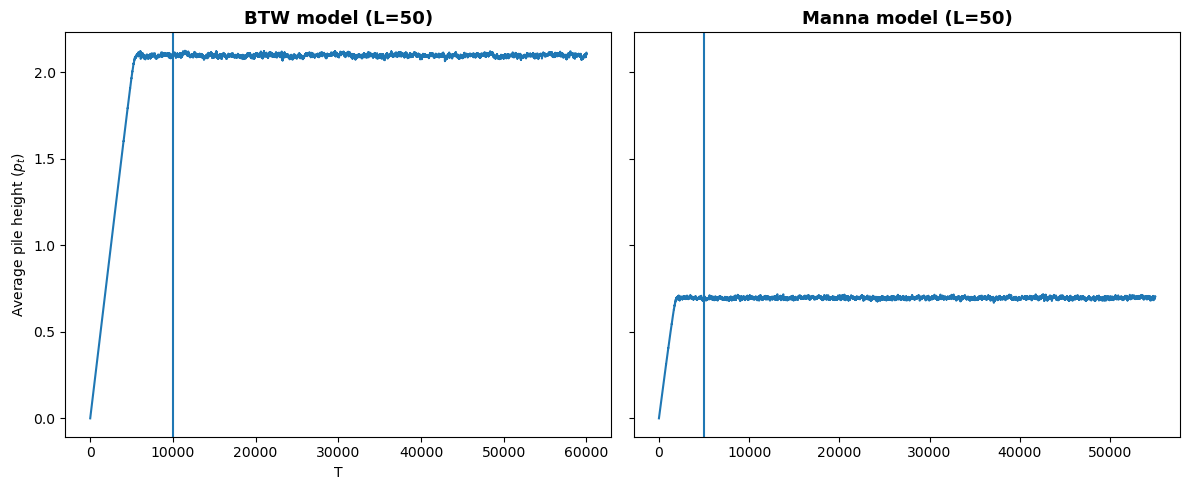

In [14]:
output_dir = Path.cwd() / "output"
output_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].plot(range(60000), average_height)
axes[0].axvline(10000)
axes[0].set_xlabel("T")
axes[0].set_ylabel(r"Average pile height ($p_t$)")
axes[0].set_title("BTW model (L=50)", fontsize=13, fontweight="bold")

axes[1].plot(range(55000), average_height_manna)
axes[1].axvline(5000)
axes[1].set_title("Manna model (L=50)", fontsize=13, fontweight="bold")

fig.tight_layout()
fig.savefig(output_dir / "average_height.pdf", bbox_inches="tight")

plt.show()

### Simulation setup

In [15]:
# BTW model 
L_values = [10, 20, 30, 40, 50]
results_by_L = {}
burn_in = 10000

for L in L_values:
    results_by_L[L] = simulate_avalanche(T=60000, width=L, height=L, 
                                         manna=False, seed=12345)
    results_by_L[L] = results_by_L[L][burn_in:, :]


In [16]:
# manna model 
L_values = [10, 20, 30, 40, 50]
results_by_L_manna = {}
burn_in = 5000

for L in L_values:
    results_by_L_manna[L] = simulate_avalanche(T=55000, width=L, height=L, 
                                               manna=True, seed=12345)
    results_by_L_manna[L] = results_by_L_manna[L][burn_in:, :]

### Correlation checks

In [17]:
btw_corr = correlations_by_L(results_by_L, L_values)
manna_corr = correlations_by_L(results_by_L_manna, L_values)

In [18]:
np.round(btw_corr[50], 3)

,Topples,Area,Loss,Length
Topples,1.000,1.000,0.626,0.963
Area,1.000,1.000,0.626,0.964
Loss,0.626,0.626,1.000,0.625
Length,0.963,0.964,0.625,1.000


In [19]:
np.round(manna_corr[50], 3)

,Topples,Area,Loss,Length
Topples,1.000,0.999,0.527,0.982
Area,0.999,1.000,0.527,0.984
Loss,0.527,0.527,1.000,0.516
Length,0.982,0.984,0.516,1.000


### Results

#### Topples

##### BTW model

In [20]:
topples_cutoffs = select_cutoff_simulation(results_by_L, L_values, "Topples")

L=10: cutoff=29.0, survival_slope=-0.598, R²=0.950
L=20: cutoff=90.0, survival_slope=-0.477, R²=0.950
L=30: cutoff=212.0, survival_slope=-0.459, R²=0.950
L=40: cutoff=339.0, survival_slope=-0.430, R²=0.950
L=50: cutoff=540.0, survival_slope=-0.421, R²=0.950


In [21]:
collapse_topples_before = collapse_deviation(L_values, topples_cutoffs, results_by_L, 
                                             "Topples", adjusted=False)

Before log(N) scaling
Slope: -1.120
  L=10: maximum=0.449
  L=20: maximum=0.504
  L=30: maximum=0.609
  L=40: maximum=1.068
  L=50: maximum=1.900
Overall maximum deviation: 1.900
Overall RMSE: 0.311


In [22]:
collapse_topples_after = collapse_deviation(L_values, topples_cutoffs, results_by_L, 
                                            "Topples", adjusted=True)

After log(N) scaling
Slope: -1.070
  L=10: maximum=0.310
  L=20: maximum=0.327
  L=30: maximum=0.610
  L=40: maximum=1.080
  L=50: maximum=1.879
Overall maximum deviation: 1.879
Overall RMSE: 0.299


##### Manna model

The following compares the fit over the full positive range with the fit after excluding the initial plateau.

In [23]:
topples_cutoffs_manna = select_cutoff_simulation(results_by_L_manna, L_values, "Topples")


L=10: cutoff=47.0, survival_slope=-0.713, R²=0.950
L=20: cutoff=261.0, survival_slope=-0.676, R²=0.950


L=30: cutoff=870.0, survival_slope=-0.696, R²=0.950
L=40: cutoff=1947.0, survival_slope=-0.680, R²=0.950
L=50: cutoff=3288.0, survival_slope=-0.647, R²=0.950


In [24]:
collapse_topples_before_manna = collapse_deviation(L_values, topples_cutoffs_manna, 
                                                   results_by_L, "Topples", adjusted=False)
collapse_topples_after_manna = collapse_deviation(L_values, topples_cutoffs_manna, 
                                                  results_by_L, "Topples", adjusted=True)

Before log(N) scaling
Slope: -1.121
  L=10: maximum=0.529
  L=20: maximum=1.485
  L=30: maximum=1.764
  L=40: maximum=1.551
  L=50: maximum=1.817
Overall maximum deviation: 1.817
Overall RMSE: 0.478
After log(N) scaling
Slope: -1.083
  L=10: maximum=0.356
  L=20: maximum=1.661
  L=30: maximum=1.828
  L=40: maximum=1.541
  L=50: maximum=1.740
Overall maximum deviation: 1.828
Overall RMSE: 0.491


In [25]:
# refined fit excluding the initial plateau

L_values=[10,20,30,40,50]
lower_cutoff_topples_manna = get_lower_cutoff(L_values, results_by_L_manna, "Topples", 
                                              n_bins=30, bins_to_exclude=1)
lower_cutoffs_topples_manna = {L: lower_cutoff_topples_manna for L in L_values}

collapse_topples_before_manna_refit = collapse_deviation(L_values, topples_cutoffs_manna, results_by_L, 
                                                    "Topples", lower_cutoffs=lower_cutoffs_topples_manna, 
                                                    adjusted=False)

print()

collapse_topples_after_manna_refit = collapse_deviation(L_values, topples_cutoffs_manna, results_by_L, 
                                                    "Topples", lower_cutoffs=lower_cutoffs_topples_manna, 
                                                    adjusted=True)


Before log(N) scaling
Slope: -1.123
  L=10: maximum=0.524
  L=20: maximum=1.487
  L=30: maximum=1.765
  L=40: maximum=1.551
  L=50: maximum=1.818
Overall maximum deviation: 1.818
Overall RMSE: 0.478

After log(N) scaling
Slope: -1.084
  L=10: maximum=0.359
  L=20: maximum=1.662
  L=30: maximum=1.829
  L=40: maximum=1.541
  L=50: maximum=1.740
Overall maximum deviation: 1.829
Overall RMSE: 0.491


In [26]:
# common lower cutoff for all system sizes
lower_cutoff_topples_manna

np.int64(2)

##### Combined plot

In these plots we exclude the initial plateau from the Manna plots

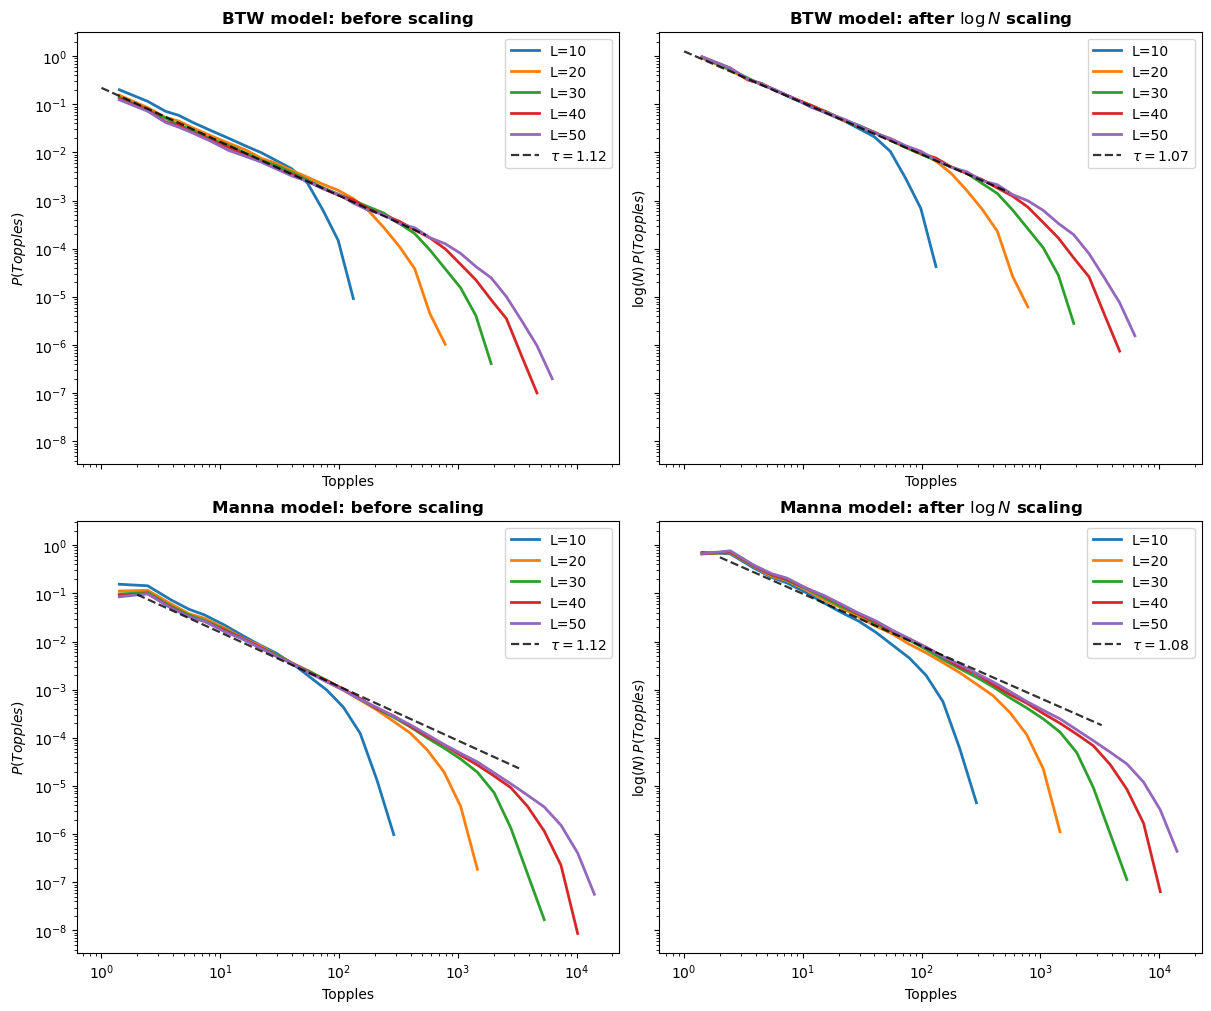

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), 
                         sharex=True, sharey=True, constrained_layout=True)

# BTW: before scaling
plot_raw_distribution(L_values, results_by_L, "Topples",
    adjustment=False, ax=axes[0, 0], fit_result=collapse_topples_before)

# BTW: after scaling
plot_raw_distribution(L_values, results_by_L, "Topples",
    adjustment=True, ax=axes[0, 1], fit_result=collapse_topples_after)

# Manna: before scaling
plot_raw_distribution(L_values, results_by_L_manna, "Topples",
    adjustment=False, ax=axes[1, 0], fit_result=collapse_topples_before_manna_refit)

# Manna: after scaling
plot_raw_distribution(L_values, results_by_L_manna, "Topples",
    adjustment=True, ax=axes[1, 1], fit_result=collapse_topples_after_manna_refit)

axes[0, 0].set_title("BTW model: before scaling", fontweight="bold")
axes[0, 1].set_title(r"BTW model: after $\log N$ scaling", fontweight="bold")

axes[1, 0].set_title("Manna model: before scaling", fontweight="bold")
axes[1, 1].set_title(r"Manna model: after $\log N$ scaling", fontweight="bold")

fig.savefig(output_dir / "topples.pdf", bbox_inches="tight")

plt.show()

#### Area

##### BTW model

In [28]:
# cutoff points for each grid with size L

area_cutoffs = select_cutoff_simulation(results_by_L, L_values, "Area")

L=10: cutoff=27.0, survival_slope=-0.590, R²=0.951
L=20: cutoff=78.0, survival_slope=-0.470, R²=0.950
L=30: cutoff=177.0, survival_slope=-0.455, R²=0.950
L=40: cutoff=269.0, survival_slope=-0.424, R²=0.950
L=50: cutoff=424.0, survival_slope=-0.417, R²=0.950


In [29]:
collapse_area_before = collapse_deviation(L_values, area_cutoffs, results_by_L, 
                                          "Area", adjusted=False)

Before log(N) scaling
Slope: -1.106
  L=10: maximum=0.493
  L=20: maximum=0.433
  L=30: maximum=0.659
  L=40: maximum=0.897
  L=50: maximum=1.263
Overall maximum deviation: 1.263
Overall RMSE: 0.270


In [30]:
collapse_area_after = collapse_deviation(L_values, area_cutoffs, results_by_L, 
                                         "Area", adjusted=True)

After log(N) scaling
Slope: -1.054
  L=10: maximum=0.283
  L=20: maximum=0.282
  L=30: maximum=0.698
  L=40: maximum=0.910
  L=50: maximum=1.252
Overall maximum deviation: 1.252
Overall RMSE: 0.256


##### Manna model

Again we compute fit with and without the initial plateau.

In [31]:
area_cutoffs_manna = select_cutoff_simulation(results_by_L_manna, L_values, "Area")

L=10: cutoff=23.0, survival_slope=-0.693, R²=0.951
L=20: cutoff=100.0, survival_slope=-0.688, R²=0.950
L=30: cutoff=246.0, survival_slope=-0.702, R²=0.950


L=40: cutoff=478.0, survival_slope=-0.714, R²=0.950
L=50: cutoff=721.0, survival_slope=-0.699, R²=0.950


In [32]:
collapse_area_before_manna = collapse_deviation(L_values, area_cutoffs_manna, results_by_L, 
                                                "Area", adjusted=False)
print()
collapse_area_after_manna = collapse_deviation(L_values, area_cutoffs_manna, results_by_L, 
                                                "Area", adjusted=True)

Before log(N) scaling
Slope: -1.127
  L=10: maximum=0.340
  L=20: maximum=0.519
  L=30: maximum=0.956
  L=40: maximum=1.768
  L=50: maximum=1.674
Overall maximum deviation: 1.768
Overall RMSE: 0.365

After log(N) scaling
Slope: -1.083
  L=10: maximum=0.397
  L=20: maximum=0.396
  L=30: maximum=1.047
  L=40: maximum=1.800
  L=50: maximum=1.652
Overall maximum deviation: 1.800
Overall RMSE: 0.358


In [33]:
# lower cutoff to exclude plateau

L_values=[10,20,30,40,50]
lower_cutoff_area_manna = get_lower_cutoff(L_values, results_by_L_manna, "Area", n_bins=30, bins_to_exclude=1)
lower_cutoffs_area_manna = {L: lower_cutoff_area_manna for L in L_values}

collapse_area_before_manna_refit = collapse_deviation(L_values, area_cutoffs_manna, results_by_L, 
                                                    "Area", lower_cutoffs=lower_cutoffs_area_manna, adjusted=False)

print()

collapse_area_after_manna_refit = collapse_deviation(L_values, area_cutoffs_manna, results_by_L, 
                                                    "Area", lower_cutoffs=lower_cutoffs_area_manna, adjusted=True)


Before log(N) scaling
Slope: -1.133
  L=10: maximum=0.324
  L=20: maximum=0.514
  L=30: maximum=0.956
  L=40: maximum=1.764
  L=50: maximum=1.670
Overall maximum deviation: 1.764
Overall RMSE: 0.365

After log(N) scaling
Slope: -1.088
  L=10: maximum=0.258
  L=20: maximum=0.337
  L=30: maximum=1.047
  L=40: maximum=1.797
  L=50: maximum=1.649
Overall maximum deviation: 1.797
Overall RMSE: 0.358


In [34]:
lower_cutoff_area_manna

np.int64(2)

##### Combined plot

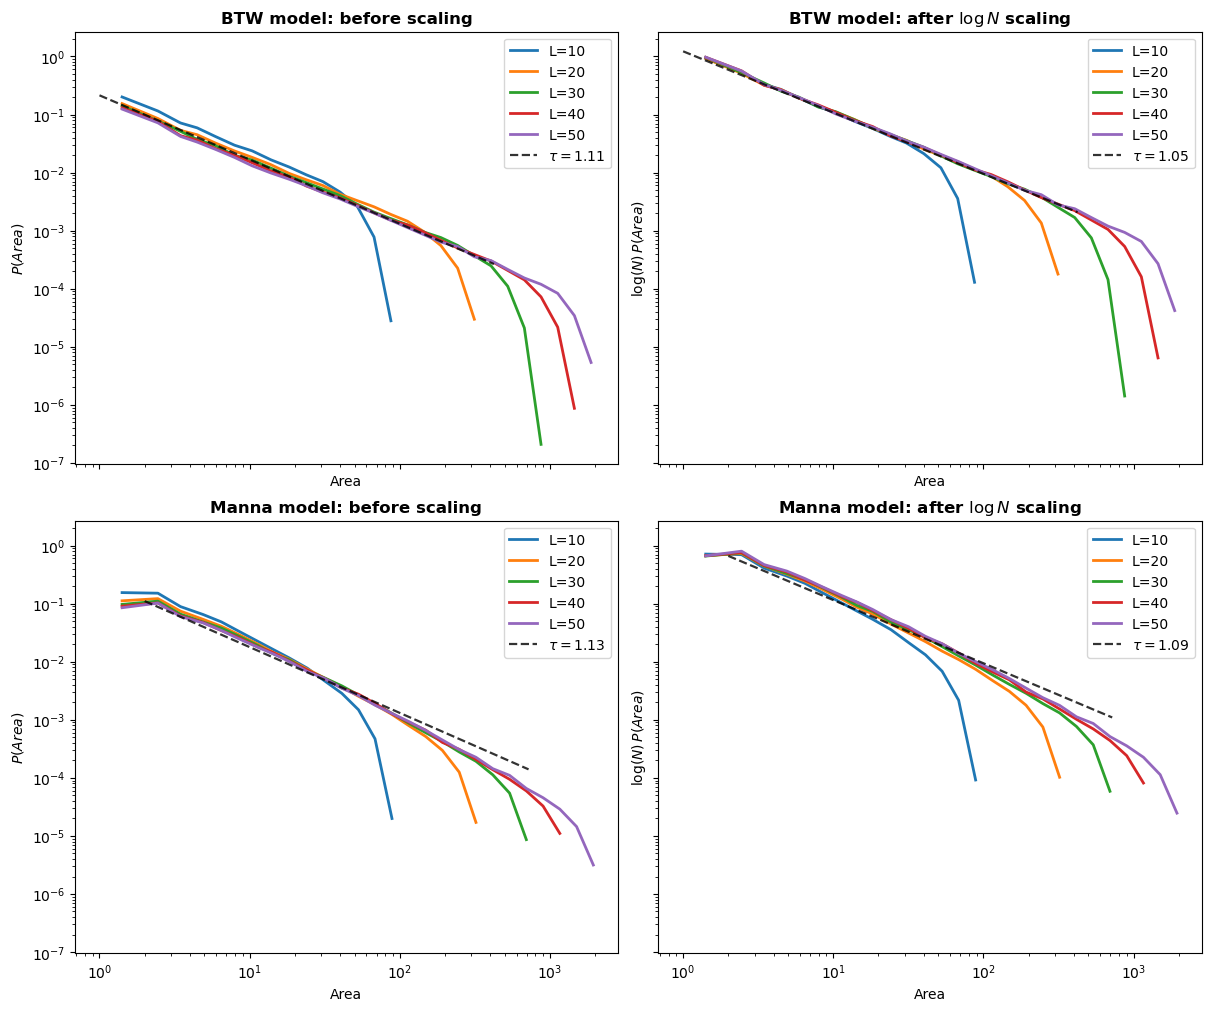

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10),
                        sharex=True, sharey=True, constrained_layout=True)

# BTW: before scaling
plot_raw_distribution(L_values, results_by_L, "Area",
    adjustment=False, ax=axes[0, 0], fit_result=collapse_area_before)

# BTW: after scaling
plot_raw_distribution(L_values, results_by_L, "Area",
    adjustment=True, ax=axes[0, 1], fit_result=collapse_area_after)

# Manna: before scaling
plot_raw_distribution(L_values, results_by_L_manna, "Area",
    adjustment=False, ax=axes[1, 0], fit_result=collapse_area_before_manna_refit)

# Manna: after scaling
plot_raw_distribution(L_values, results_by_L_manna, "Area",
    adjustment=True, ax=axes[1, 1], fit_result=collapse_area_after_manna_refit
)

axes[0, 0].set_title("BTW model: before scaling", fontweight="bold")
axes[0, 1].set_title(r"BTW model: after $\log N$ scaling", fontweight="bold")

axes[1, 0].set_title("Manna model: before scaling", fontweight="bold")
axes[1, 1].set_title(r"Manna model: after $\log N$ scaling", fontweight="bold")

fig.savefig(output_dir / "area.pdf", bbox_inches="tight")

plt.show()

#### Loss

In [36]:
# BTW model
loss_results = fit_exp_sim(results_by_L, L_values, "Loss")

L=10: P(Loss=0)=0.723, lambda=0.327, R²=0.992
L=20: P(Loss=0)=0.766, lambda=0.227, R²=0.953
L=30: P(Loss=0)=0.793, lambda=0.163, R²=0.936
L=40: P(Loss=0)=0.816, lambda=0.137, R²=0.905
L=50: P(Loss=0)=0.826, lambda=0.137, R²=0.929


In [37]:
# Manna model
loss_results_manna = fit_exp_sim(results_by_L_manna, L_values, "Loss")

L=10: P(Loss=0)=0.589, lambda=0.474, R²=0.994
L=20: P(Loss=0)=0.676, lambda=0.252, R²=0.939
L=30: P(Loss=0)=0.724, lambda=0.199, R²=0.952
L=40: P(Loss=0)=0.758, lambda=0.145, R²=0.930
L=50: P(Loss=0)=0.785, lambda=0.118, R²=0.902


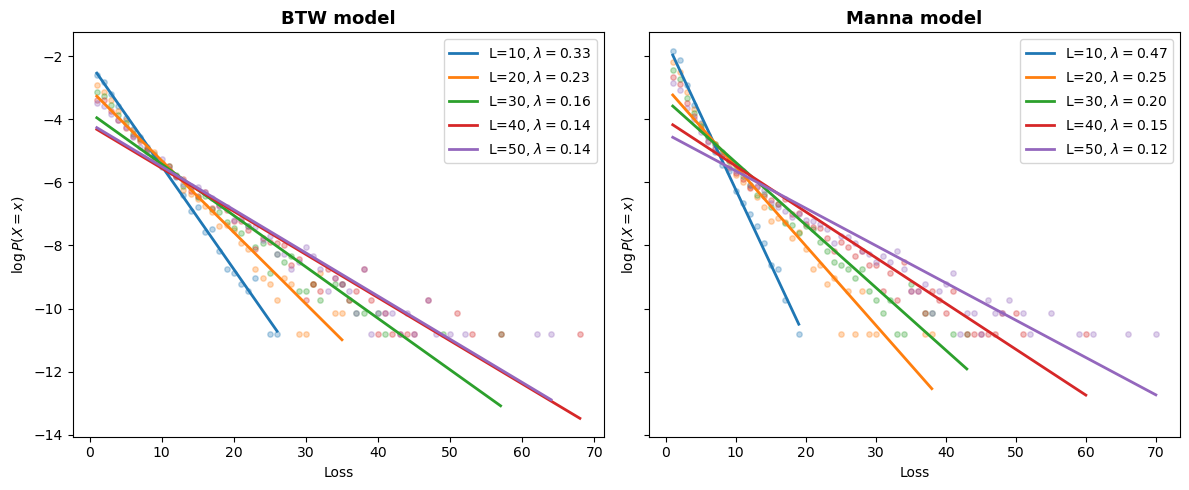

In [38]:
# positive loss distribution

output_dir = Path.cwd() / "output"
output_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

plot_exp_sim(loss_results, L_values, "Loss", ax=axes[0])
plot_exp_sim(loss_results_manna, L_values, "Loss", ax=axes[1])

axes[0].set_title("BTW model", fontsize=13, fontweight="bold")
axes[1].set_title("Manna model", fontsize=13, fontweight="bold")

fig.tight_layout()
fig.savefig(output_dir / "positive_loss.pdf", bbox_inches="tight")

plt.show()


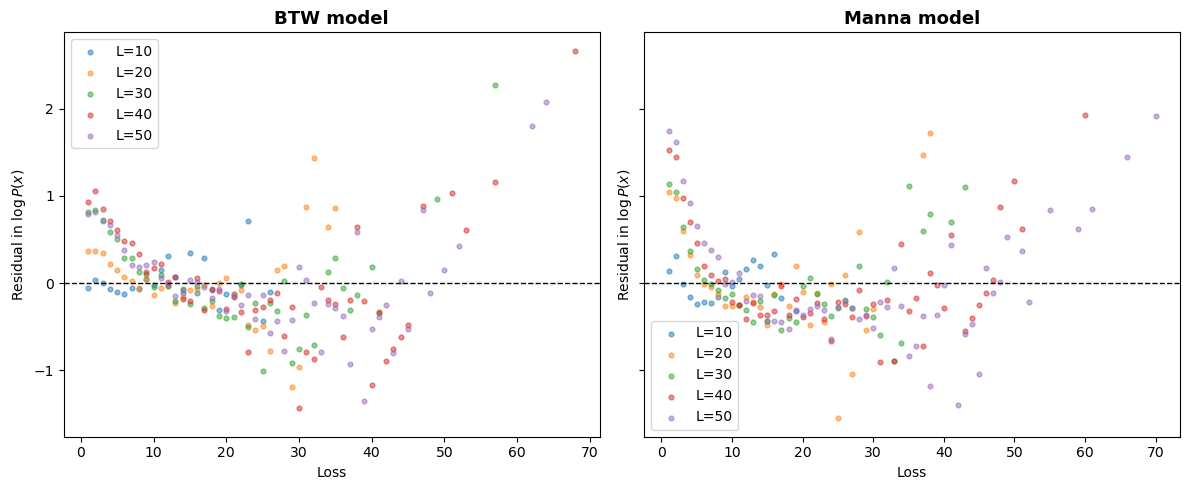

In [39]:
# loss residual diagnostics plot

output_dir = Path.cwd() / "output"
output_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

show_exp_diagnostic(L_values, loss_results, "Loss", ax=axes[0])
show_exp_diagnostic(L_values, loss_results_manna, "Loss", ax=axes[1])

axes[0].set_title("BTW model", fontsize=13, fontweight="bold")
axes[1].set_title("Manna model", fontsize=13, fontweight="bold")

fig.tight_layout()
fig.savefig(output_dir / "loss_resid.pdf", bbox_inches="tight")

plt.show()

#### Length

##### Power law

In [40]:
# BTW model
length_cutoffs = select_cutoff_simulation(results_by_L, L_values, "Length", 
                                        min_points=8, r2_threshold=0.88)

L=10: cutoff=8.0, survival_slope=-0.770, R²=0.880
L=20: cutoff=15.0, survival_slope=-0.675, R²=0.885
L=30: cutoff=24.0, survival_slope=-0.696, R²=0.882
L=40: cutoff=32.0, survival_slope=-0.682, R²=0.884
L=50: cutoff=40.0, survival_slope=-0.675, R²=0.882


In [41]:
# BTW model
collapse_length_before = collapse_deviation(L_values, length_cutoffs, results_by_L, 
                                            "Length", adjusted=False)
collapse_length_after = collapse_deviation(L_values, length_cutoffs, results_by_L, 
                                            "Length", adjusted=True)

Before log(N) scaling
Slope: -0.884
  L=10: maximum=0.600
  L=20: maximum=0.532
  L=30: maximum=0.640
  L=40: maximum=0.701
  L=50: maximum=0.766
Overall maximum deviation: 0.766
Overall RMSE: 0.223
After log(N) scaling
Slope: -0.816
  L=10: maximum=0.446
  L=20: maximum=0.524
  L=30: maximum=0.505
  L=40: maximum=0.484
  L=50: maximum=0.490
Overall maximum deviation: 0.524
Overall RMSE: 0.152


In [42]:
# Manna model
length_cutoffs_manna = select_cutoff_simulation(results_by_L_manna, L_values, "Length", 
                                                min_points=8, r2_threshold=0.88)

L=10: cutoff=8.0, survival_slope=-0.895, R²=0.890
L=20: cutoff=18.0, survival_slope=-0.990, R²=0.881
L=30: cutoff=28.0, survival_slope=-1.031, R²=0.882
L=40: cutoff=39.0, survival_slope=-1.075, R²=0.882
L=50: cutoff=50.0, survival_slope=-1.115, R²=0.883


In [43]:
# Manna model
collapse_length_before_manna = collapse_deviation(L_values, length_cutoffs_manna, 
                                                results_by_L, "Length", adjusted=False)
collapse_length_after_manna = collapse_deviation(L_values, length_cutoffs_manna, 
                                                results_by_L, "Length", adjusted=True)

Before log(N) scaling
Slope: -0.934
  L=10: maximum=0.603
  L=20: maximum=0.624
  L=30: maximum=0.732
  L=40: maximum=0.793
  L=50: maximum=0.858
Overall maximum deviation: 0.858
Overall RMSE: 0.228
After log(N) scaling
Slope: -0.869
  L=10: maximum=0.539
  L=20: maximum=0.616
  L=30: maximum=0.597
  L=40: maximum=0.576
  L=50: maximum=0.583
Overall maximum deviation: 0.616
Overall RMSE: 0.171


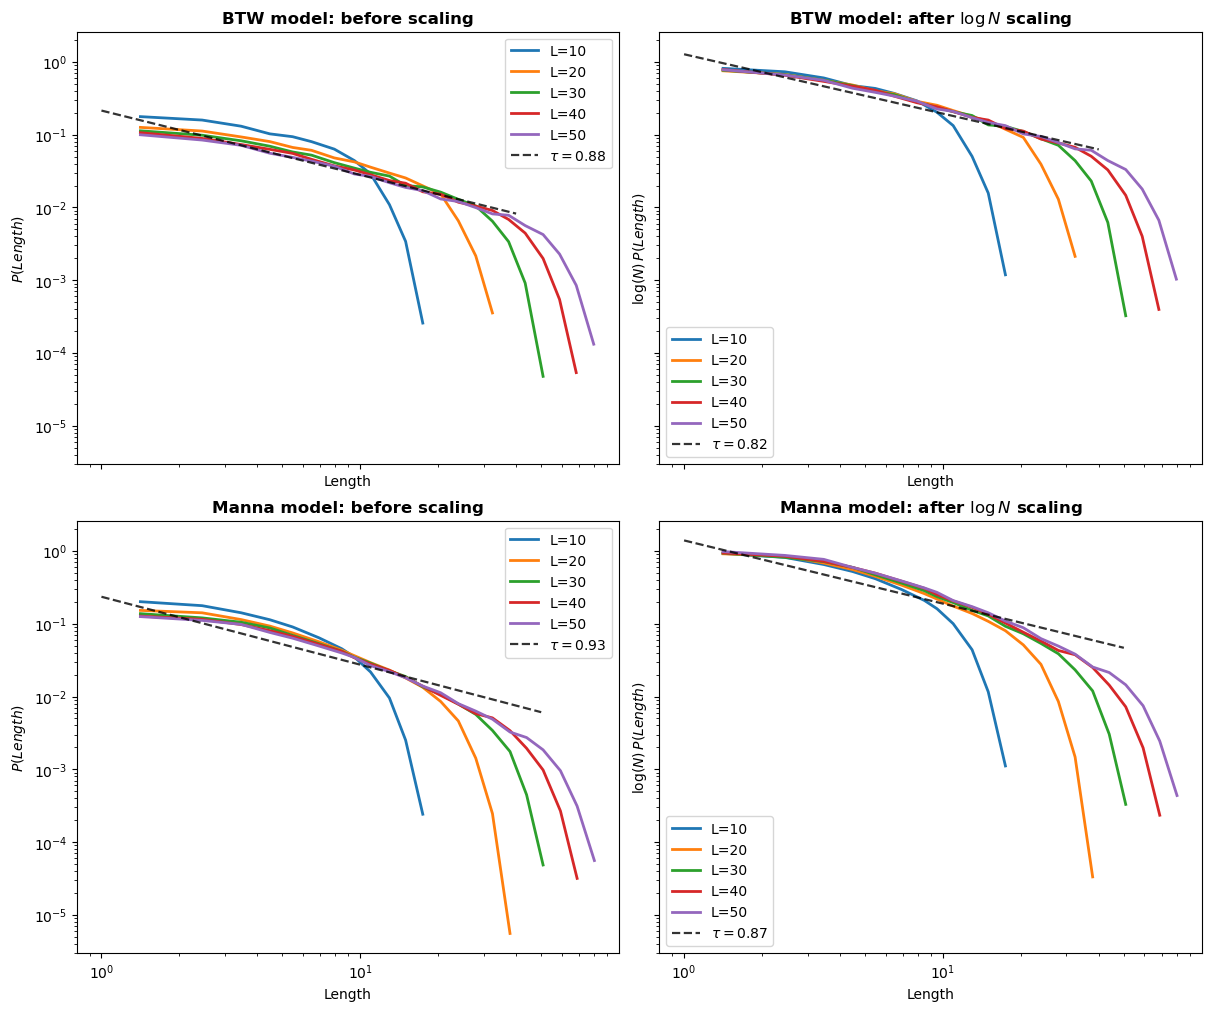

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), 
    sharex=True, sharey=True, constrained_layout=True)

# BTW: before scaling
plot_raw_distribution(L_values, results_by_L, "Length",
    adjustment=False, ax=axes[0, 0], fit_result=collapse_length_before)

# BTW: after scaling
plot_raw_distribution(L_values, results_by_L, "Length",
    adjustment=True, ax=axes[0, 1], fit_result=collapse_length_after)

# Manna: before scaling
plot_raw_distribution(L_values, results_by_L_manna, "Length",
    adjustment=False, ax=axes[1, 0], fit_result=collapse_length_before_manna)

# Manna: after scaling
plot_raw_distribution(L_values, results_by_L_manna, "Length",
    adjustment=True, ax=axes[1, 1], fit_result=collapse_length_after_manna)

axes[0, 0].set_title("BTW model: before scaling", fontweight="bold")
axes[0, 1].set_title(r"BTW model: after $\log N$ scaling", fontweight="bold")

axes[1, 0].set_title("Manna model: before scaling", fontweight="bold")
axes[1, 1].set_title(r"Manna model: after $\log N$ scaling", fontweight="bold")

fig.savefig(output_dir / "length_powerlaw.pdf", bbox_inches="tight")

plt.show()

##### Exponential

In [45]:
# BTW model
length_results = fit_exp_sim(results_by_L, L_values, "Length")

L=10: P(Length=0)=0.689, lambda=0.417, R²=0.863
L=20: P(Length=0)=0.651, lambda=0.173, R²=0.914
L=30: P(Length=0)=0.633, lambda=0.127, R²=0.889
L=40: P(Length=0)=0.628, lambda=0.093, R²=0.910
L=50: P(Length=0)=0.621, lambda=0.068, R²=0.920


In [46]:
# Manna model
length_results_manna = fit_exp_sim(results_by_L_manna, L_values, "Length")

L=10: P(Length=0)=0.448, lambda=0.390, R²=0.904
L=20: P(Length=0)=0.399, lambda=0.219, R²=0.909
L=30: P(Length=0)=0.381, lambda=0.138, R²=0.951
L=40: P(Length=0)=0.369, lambda=0.104, R²=0.952
L=50: P(Length=0)=0.365, lambda=0.085, R²=0.960


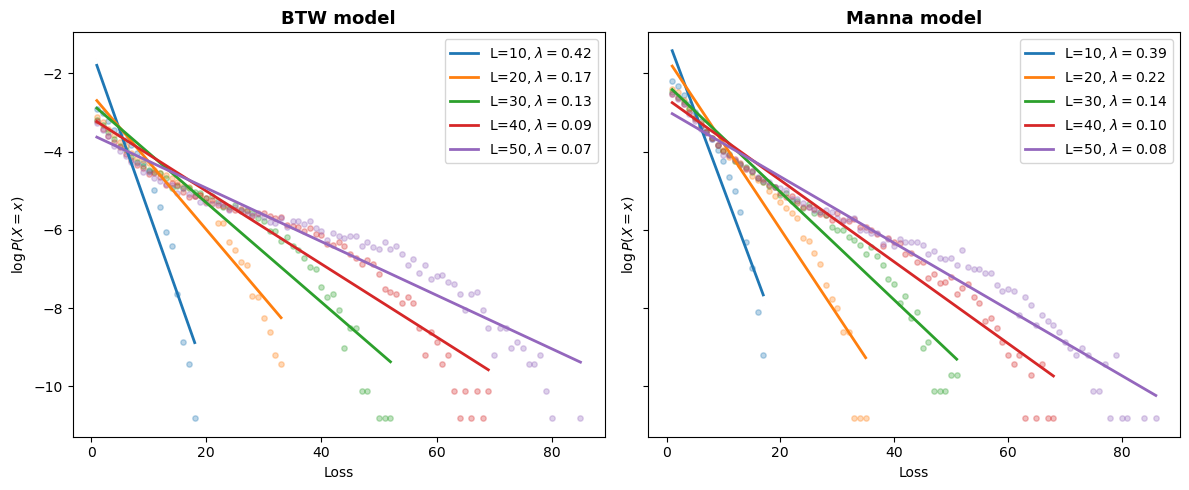

In [47]:
output_dir = Path.cwd() / "output"
output_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

plot_exp_sim(length_results, L_values, "Loss", ax=axes[0])
plot_exp_sim(length_results_manna, L_values, "Loss", ax=axes[1])

axes[0].set_title("BTW model", fontsize=13, fontweight="bold")
axes[1].set_title("Manna model", fontsize=13, fontweight="bold")

fig.tight_layout()
fig.savefig(output_dir / "positive_length.pdf", bbox_inches="tight")

plt.show()

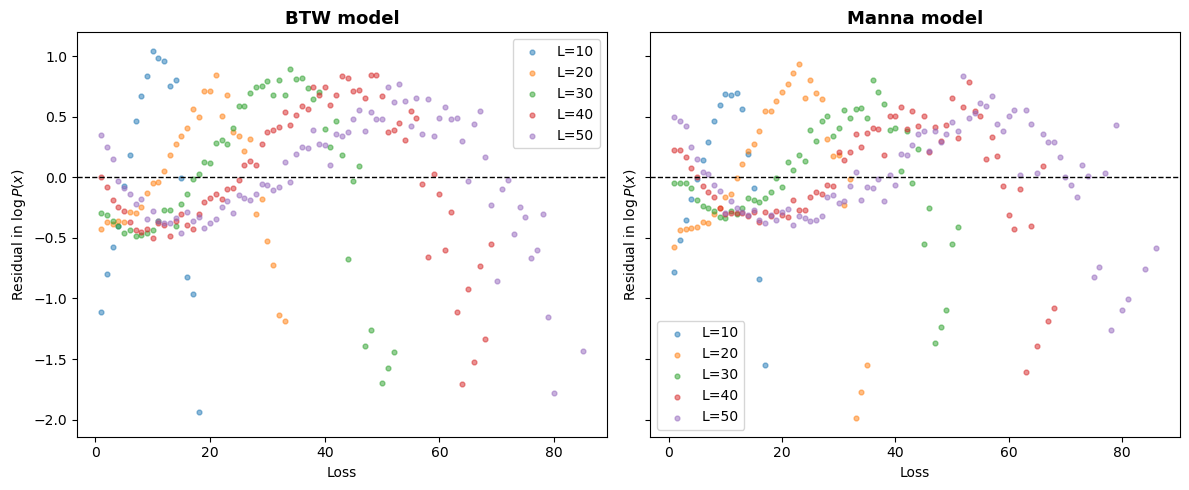

In [48]:
output_dir = Path.cwd() / "output"
output_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

show_exp_diagnostic(L_values, length_results, "Loss", ax=axes[0])
show_exp_diagnostic(L_values, length_results_manna, "Loss", ax=axes[1])

axes[0].set_title("BTW model", fontsize=13, fontweight="bold")
axes[1].set_title("Manna model", fontsize=13, fontweight="bold")

fig.tight_layout()
fig.savefig(output_dir / "length_resid.pdf", bbox_inches="tight")

plt.show()

#### Correlation matrix (L=50)

In [49]:
btw_corr = correlations_by_L(results_by_L, L_values)
manna_corr = correlations_by_L(results_by_L_manna, L_values)

In [50]:
np.round(btw_corr[50], 3)

,Topples,Area,Loss,Length
Topples,1.000,1.000,0.626,0.963
Area,1.000,1.000,0.626,0.964
Loss,0.626,0.626,1.000,0.625
Length,0.963,0.964,0.625,1.000


In [51]:
np.round(manna_corr[50], 3)

,Topples,Area,Loss,Length
Topples,1.000,0.999,0.527,0.982
Area,0.999,1.000,0.527,0.984
Loss,0.527,0.527,1.000,0.516
Length,0.982,0.984,0.516,1.000


### Appendix

#### L=10

In [52]:
np.round(btw_corr[10], 3)

,Topples,Area,Loss,Length
Topples,1.000,1.000,0.825,0.932
Area,1.000,1.000,0.825,0.932
Loss,0.825,0.825,1.000,0.789
Length,0.932,0.932,0.789,1.000


In [53]:
np.round(manna_corr[10], 3)

,Topples,Area,Loss,Length
Topples,1.000,0.998,0.683,0.963
Area,0.998,1.000,0.684,0.967
Loss,0.683,0.684,1.000,0.638
Length,0.963,0.967,0.638,1.000


#### L=20

In [54]:
np.round(btw_corr[20], 3)

,Topples,Area,Loss,Length
Topples,1.000,1.000,0.732,0.951
Area,1.000,1.000,0.732,0.952
Loss,0.732,0.732,1.000,0.718
Length,0.951,0.952,0.718,1.000


In [55]:
np.round(manna_corr[20], 3)

,Topples,Area,Loss,Length
Topples,1.000,0.999,0.607,0.975
Area,0.999,1.000,0.607,0.978
Loss,0.607,0.607,1.000,0.582
Length,0.975,0.978,0.582,1.000


#### L=30

In [56]:
np.round(btw_corr[30], 3)

,Topples,Area,Loss,Length
Topples,1.000,1.000,0.682,0.957
Area,1.000,1.000,0.682,0.957
Loss,0.682,0.682,1.000,0.676
Length,0.957,0.957,0.676,1.000


In [57]:
np.round(manna_corr[30], 3)

,Topples,Area,Loss,Length
Topples,1.000,0.999,0.572,0.978
Area,0.999,1.000,0.571,0.981
Loss,0.572,0.571,1.000,0.553
Length,0.978,0.981,0.553,1.000


#### L=40

In [58]:
np.round(btw_corr[20], 3)

,Topples,Area,Loss,Length
Topples,1.000,1.000,0.732,0.951
Area,1.000,1.000,0.732,0.952
Loss,0.732,0.732,1.000,0.718
Length,0.951,0.952,0.718,1.000


In [59]:
np.round(manna_corr[20], 3)

,Topples,Area,Loss,Length
Topples,1.000,0.999,0.607,0.975
Area,0.999,1.000,0.607,0.978
Loss,0.607,0.607,1.000,0.582
Length,0.975,0.978,0.582,1.000


### References

[1] P. Bak, C. Tang, and K. Wiesenfeld, “Self-organized criticality: An explanation of 1/f noise,” Physical Review Letters, vol. 59, pp. 381–384, 1987. doi: 10.1103/PhysRevLett.59.381. 

[2] S. S. Manna, “Two-state model of self-organized criticality,” Journal of Physics A: Mathematical and General, vol. 24, pp. L363–L369, 1991. doi: 10.1088/0305-4470/24/7/009.

[3] Python Software Foundation, “collections.deque — Container datatypes,” Python documentation. https://docs.python.org/3/library/collections.html#collections.deque